This notebook reproduces Fig. 4. Low frequency stochastic errors can be included in the Hamiltonian as
$$
\hat{H}(t) = (z(t)-\tilde{z})\hat{\sigma}_z+(x+\tilde{x})\hat{\sigma}_x,
$$
with $\tilde{z}$ and $\tilde{x}$ drawn from a Gaussian distribution, with zero mean and standard deviation given by $\delta_z$ and $\delta_x$, respectively. The pulses are obtained for the noiseless Hamiltonian (see `Fig02-LZ.ipynb`), and the fidelity is averaged over independent realizations of the quasi-static noise. Energies are given in units of $x$, and times in units of $\hbar/x$. The vertical red dashed line denotes the geometric fast-QUAD ($n_+=2$).

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from parameterrun import parameterrun
from tqdm.auto import tqdm

from HQUAD_lib.physics_utils import fidelity_LZ
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
delta_x = x / 10
delta_z = x / 10

alphas = np.linspace(
    -2, 10, 25
)  # Increase number of samples to improve resolution (144 values in the manuscript)
betas = alphas
n_plus = (alphas + betas) / 2

tfs = np.linspace(
    0.1, 30, 100
)  # Increase number of samples to improve resolution (200 values in the manuscript)

n_runs = 20  # Increase number of runs to get more stable results (200 runs in the manuscript)

rng = np.random.default_rng(seed=0)

In [3]:
def compute_fidelity_total(
    alpha: float, beta: float, delta_x: float, delta_z: float
) -> np.ndarray:
    z_sol = solve_LZ(alpha, beta, x=x)

    n_runs_int = 1 if (delta_x == 0) and (delta_z == 0) else n_runs

    fidelities = []
    for _ in tqdm(range(n_runs_int), desc="    Iterating over noise", leave=False):
        x_bar = rng.normal(scale=delta_x)
        z_bar = rng.normal(scale=delta_z)

        fidelities.append(
            np.asarray(
                parameterrun(
                    fidelity_LZ,
                    "tf",
                    tfs,
                    pulse=z_sol,
                    x=x,
                    z0=-10,
                    x_bar=x_bar,
                    z_bar=z_bar,
                    pbar_bool=False,
                )
            )
        )

    return np.average(fidelities, axis=0)

In [4]:
fidelities = np.zeros((len(alphas), len(tfs)))
fidelities_x = np.zeros((len(alphas), len(tfs)))
fidelities_z = np.zeros((len(alphas), len(tfs)))

for i in tqdm(range(len(alphas)), desc="Iterating over alpha"):
    fidelities[i] = compute_fidelity_total(alphas[i], betas[i], 0, 0)
    fidelities_x[i] = compute_fidelity_total(alphas[i], betas[i], delta_x, 0)
    fidelities_z[i] = compute_fidelity_total(alphas[i], betas[i], 0, delta_z)

Iterating over alpha:   0%|          | 0/25 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/1 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/1 [00:00<?, ?it/s]

...

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/1 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

    Iterating over noise:   0%|          | 0/20 [00:00<?, ?it/s]

# Plot

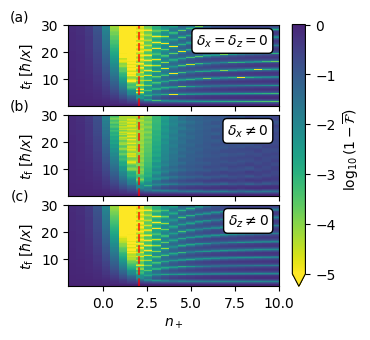

In [5]:
cmap_fidelity = ListedColormap(mpl.colormaps["viridis_r"](np.linspace(0, 0.9, 256)))

fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(3.4, 3.4))

images = []
texts = [r"$\delta_x=\delta_z = 0$", r"$\delta_x \neq 0$", r"$\delta_z \neq 0$"]
for ax, fidelities_i, text in zip(axs, [fidelities, fidelities_x, fidelities_z], texts):
    image = ax.imshow(
        # Infidelities below the lower limit of the color scale are shown with its lowest color
        np.log10(np.clip(1 - fidelities_i, 1e-5, None)).T,
        aspect="auto",
        origin="lower",
        interpolation="none",
        vmin=-5,
        vmax=0,
        extent=(min(n_plus), max(n_plus), min(tfs), max(tfs)),
        cmap=cmap_fidelity,
    )
    images.append(image)

    ax.text(
        0.95,
        0.9,
        text,
        ha="right",
        transform=ax.transAxes,
        va="top",
        bbox={"boxstyle": "round", "ec": "k", "fc": "w", "alpha": 1},
    )

    ax.set_ylabel(r"$t_\mathrm{f} \; [\hbar / x]$")
    ax.axvline(2, color="r", ls="--", alpha=0.7)

axs[2].set_xlabel(r"$n_+$")
axs[2].set_ylim(min(tfs), 30)

fig.subplots_adjust(hspace=0.1)
fig.colorbar(
    images[-1],
    ax=axs,
    label=r"$\log_{10}(1 - \overline{\mathcal{F}})$",
    extend="min",
)

add_labels(axs, [-0.23, 1.1])